In [2]:
import re
import numpy as np
import matplotlib.pyplot as plt

from gensim.models import Word2Vec
from sklearn.decomposition import PCA

print("Word2Vec setup complete!")

Word2Vec setup complete!


In [3]:
sentences = [
    # Royalty
    "king queen prince princess royal kingdom palace",
    "the king rules the kingdom from his royal palace",
    "the queen is the wife of the king",
    "the prince is the son of the king and queen",
    "the princess is the daughter of the king and queen",
    "the king and queen live in the palace",
    "the prince and princess belong to the royal family",

    # People
    "man woman boy girl person people",
    "the man is strong and the woman is strong",
    "the boy is young and the girl is young",
    "the man is the father of the boy",
    "the woman is the mother of the girl",
    "a boy grows into a man",
    "a girl grows into a woman",

    # Countries and cities
    "paris is the capital of france",
    "berlin is the capital of germany",
    "rome is the capital of italy",
    "france paris french europe",
    "germany berlin german europe",
    "italy rome italian europe",
    "people in france speak french",
    "people in germany speak german",
    "people in italy speak italian",
    "paris berlin and rome are european cities",

    # Animals
    "cat dog animal pet puppy kitten",
    "a cat is a small domestic animal",
    "a kitten is a young cat",
    "a puppy is a young dog",
    "dogs and cats are popular pets",
    "a dog is a loyal animal",
    "a cat can be a friendly pet",
    "puppies and kittens are young animals",

    # Machine learning
    "machine learning is a branch of artificial intelligence",
    "artificial intelligence allows machines to perform intelligent tasks",
    "deep learning is a branch of machine learning",
    "neural networks are used in deep learning",
    "a neural network contains interconnected neurons",
    "machine learning models learn patterns from data",
    "deep learning models learn complex patterns",
    "training data is used to train machine learning models",
    "artificial neural networks are inspired by the human brain",
    "data science uses statistics and machine learning",
    "a trained model makes predictions on new data",
    "natural language processing helps computers understand text",
    "computer vision helps machines understand images",
    "deep learning is used in computer vision and natural language processing",
]

# Repeat the corpus to provide more training examples
sentences = sentences * 100

print("Number of sentences:", len(sentences))
print("Example:", sentences[0])

Number of sentences: 4600
Example: king queen prince princess royal kingdom palace


In [4]:
def tokenize(text):
    return re.findall(r"\b[a-z]+\b", text.lower())

tokenized_sentences = [
    tokenize(sentence)
    for sentence in sentences
]

print("Tokenized example:", tokenized_sentences[0])

Tokenized example: ['king', 'queen', 'prince', 'princess', 'royal', 'kingdom', 'palace']


In [5]:
word2vec_model = Word2Vec(
    sentences=tokenized_sentences,
    vector_size=50,
    window=2,
    min_count=1,
    sg=1,
    workers=4,
    epochs=50,
    seed=42
)

word2vec_vectors = word2vec_model.wv

print("Vocabulary size:", len(word2vec_vectors))
print("Embedding dimensions:", word2vec_vectors.vector_size)

Vocabulary size: 117
Embedding dimensions: 50


In [6]:
word = "king"

vector = word2vec_vectors[word]

print("Word:", word)
print("Vector shape:", vector.shape)
print("First 10 values:", vector[:10])

Word: king
Vector shape: (50,)
First 10 values: [-0.20412539 -0.97644174 -0.8325122  -0.57885176  0.40751803  0.542813
 -0.72463816  0.62858266 -0.36819053  0.82251614]


In [7]:
pairs = [
    ("king", "queen"),
    ("king", "man"),
    ("paris", "france"),
    ("machine", "learning"),
    ("cat", "dog"),
]

for word1, word2 in pairs:
    score = word2vec_vectors.similarity(word1, word2)
    print(f"{word1:10s} ↔ {word2:10s}: {score:.4f}")

king       ↔ queen     : 0.6921
king       ↔ man       : 0.3698
paris      ↔ france    : 0.5014
machine    ↔ learning  : 0.6490
cat        ↔ dog       : 0.5659


In [8]:
def most_similar(word, top_k=5):
    return word2vec_vectors.most_similar(word, topn=top_k)

for word in ["queen", "france", "machine", "german"]:
    print(f"\nNearest neighbors of '{word}':")

    for neighbor, score in most_similar(word):
        print(f"  {neighbor:15s} {score:.4f}")


Nearest neighbors of 'queen':
  king            0.6921
  palace          0.6415
  princess        0.5968
  son             0.5845
  prince          0.5761

Nearest neighbors of 'france':
  french          0.6984
  italy           0.6315
  germany         0.5974
  mother          0.5097
  speak           0.5049

Nearest neighbors of 'machine':
  learning        0.6490
  data            0.6171
  complex         0.5980
  science         0.5627
  training        0.5416

Nearest neighbors of 'german':
  germany         0.7075
  italian         0.6517
  french          0.6350
  speak           0.5501
  person          0.5261


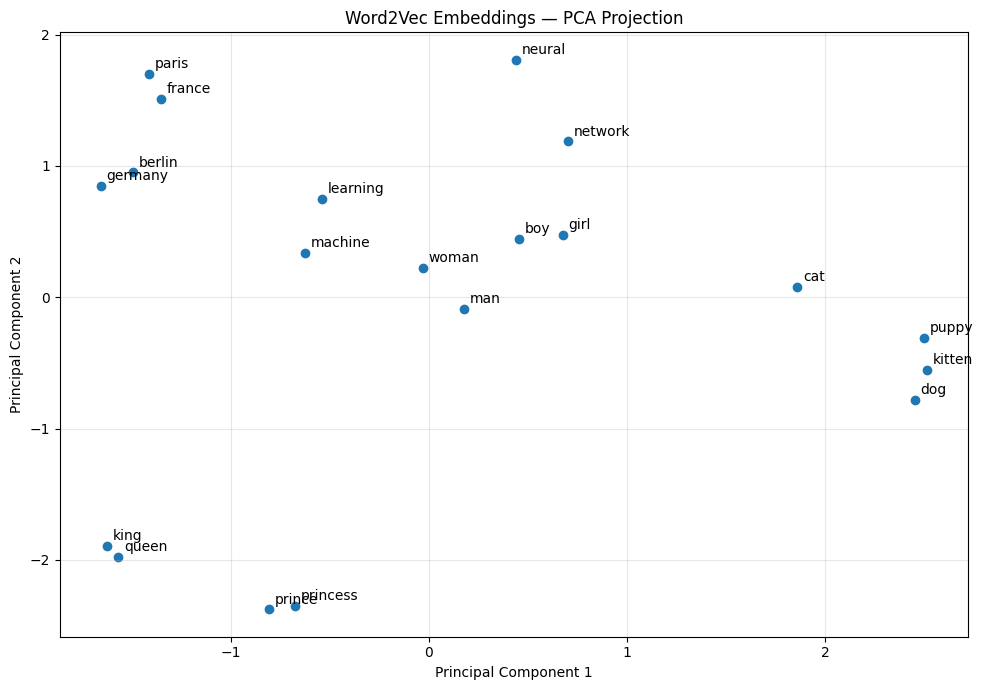

In [9]:
words_to_plot = [
    "king", "queen", "prince", "princess",
    "man", "woman", "boy", "girl",
    "paris", "france", "berlin", "germany",
    "cat", "dog", "puppy", "kitten",
    "machine", "learning", "neural", "network"
]

vectors = np.stack([
    word2vec_vectors[word]
    for word in words_to_plot
])

points_2d = PCA(n_components=2).fit_transform(vectors)

plt.figure(figsize=(10, 7))
plt.scatter(points_2d[:, 0], points_2d[:, 1])

for i, word in enumerate(words_to_plot):
    plt.annotate(
        word,
        (points_2d[i, 0], points_2d[i, 1]),
        xytext=(4, 4),
        textcoords="offset points"
    )

plt.title("Word2Vec Embeddings — PCA Projection")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()